# MINT: R (`mixOmics`) vs Python (`pythomics`)

Este notebook ejecuta el mismo MINT sobre el mismo dataset con las dos
implementaciones y compara loadings, variates, iteraciones y variables
seleccionadas.

- **R**: `MINTRWrapper` -> `mixOmics::mint.block.splsda`.
- **Python**: `pythomics.models.MINT`.
- **Datos**: `nutrimouse`, con `Y = diet` y `study = genotype`.

La versión script de todo esto es `mint_r_vs_python.py`.

In [1]:
import sys
from pathlib import Path


def _find_project_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, Path.home() / "omics"]
    for candidate in candidates:
        if (candidate / "pythomics").is_dir():
            return candidate
    raise RuntimeError("No se encontró la raíz del repo (pythomics/).")


ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

version = f"python{sys.version_info.major}.{sys.version_info.minor}"
for venv in [ROOT / ".venv", ROOT.parent / ".venv", Path.home() / ".venv"]:
    site = venv / "lib" / version / "site-packages"
    if (site / "numpy").exists() and str(site) not in sys.path:
        sys.path.append(str(site))
        print(f"Usando dependencias de {venv}")
        break

import shutil

import pandas as pd
from IPython.display import Image, display

import mint_r_vs_python as demo

OUT_DIR = ROOT / "results" / "mint_r_vs_python"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repo root :", ROOT)
print("CWD       :", Path.cwd())
print("Python    :", sys.executable)
print("Rscript   :", shutil.which("Rscript"))
print("mixOmics  :", demo.r_mixomics_version())

Repo root : /home/sephir/omics
CWD       : /home/sephir/omics
Python    : /home/sephir/.venv/bin/python
Rscript   : /usr/bin/Rscript
mixOmics  : 6.34.0


## 1. Datos

`nutrimouse` tiene 40 muestras, dos bloques (`gene`: 120 variables,
`lipid`: 21 variables), una respuesta `diet` con 5 clases y un estudio
`genotype` con 2 niveles (`wt`, `ppar`).

In [2]:
X_dict, Y, genotype = demo.load_nutrimouse(OUT_DIR)
study = demo.make_study("genotype", len(Y), genotype)

print("Muestras :", len(Y))
print("Bloques  :", {k: v.shape for k, v in X_dict.items()})
print("Dietas   :", dict(pd.Series(Y).value_counts()))
print("Estudios :", dict(pd.Series(study).value_counts()))
pd.crosstab(pd.Series(study, name="study"), pd.Series(Y, name="diet"))

Muestras : 40
Bloques  : {'gene': (40, 120), 'lipid': (40, 21)}
Dietas   : {'lin': np.int64(8), 'sun': np.int64(8), 'fish': np.int64(8), 'ref': np.int64(8), 'coc': np.int64(8)}
Estudios : {'wt': np.int64(20), 'ppar': np.int64(20)}


diet,coc,fish,lin,ref,sun
study,,,,,
ppar,4,4,4,4,4
wt,4,4,4,4,4


## 2. R / `mixOmics`

`MINTRWrapper` escribe los datos a CSVs temporales, genera un script R y
ejecuta `mint.block.splsda` (porque `Y` es categórico). Con `backend="auto"`
usa `rpy2` si está disponible y, si no, `Rscript`.

In [3]:
keep = {"gene": [15, 15], "lipid": [8, 8]}

r_model = None
try:
    r_model = demo.MINTRWrapper(
        n_components=2,
        keepX=keep,
        scale=True,
        max_iter=100,
        tol=1e-6,
        backend="auto",
    ).fit(X_dict, Y=Y, study=study)
except Exception as exc:
    print("No se pudo ejecutar MINT en R:", repr(exc))
    print("Se continúa solo con Python.")
else:
    print("Backend :", r_model.backend_)
    print("ncomp   :", r_model.n_components_)
    print("iter    :", r_model.iter_)
    for block in r_model.block_names_:
        nz = int((r_model.loadings_[block][:, 0] != 0).sum())
        print(
            f"[{block}] loadings={r_model.loadings_[block].shape}, "
            f"variates={r_model.variates_[block].shape}, nz_comp1={nz}"
        )

Backend : rscript
ncomp   : [2, 2]
iter    : [7, 6]
[gene] loadings=(120, 2), variates=(40, 2), nz_comp1=15
[lipid] loadings=(21, 2), variates=(40, 2), nz_comp1=8


## 3. Python / `pythomics`

La implementación pura usa `tau=None` (ruta MINT), `keepA` en lugar de
`keepX`, y agrega `Y` como bloque supervisado.

In [4]:
py_model = demo.MINT(
    n_components=2,
    keepA=keep,
    tau=None,
    scheme="horst",
    mode="canonical",
    scale=True,
    max_iter=100,
    tol=1e-6,
    init="svd.single",
).fit(X_dict, Y=Y, study=study)

print("ncomp :", py_model.n_components_)
print("iter  :", py_model._mint_result.iter)
for block in py_model.block_names_:
    nz = int((py_model.loadings_[block][:, 0] != 0).sum())
    print(
        f"[{block}] loadings={py_model.loadings_[block].shape}, "
        f"variates={py_model.variates_[block].shape}, nz_comp1={nz}"
    )

ncomp : [2, 2]
iter  : [7, 6]
[gene] loadings=(120, 2), variates=(40, 2), nz_comp1=15
[lipid] loadings=(21, 2), variates=(40, 2), nz_comp1=8


## 4. Comparación

Se usa el valor absoluto porque los componentes tienen ambigüedad de signo.

| Métrica | Ideal |
|---|---|
| `loading_cos_abs` | 1.0 |
| `loading_corr_abs` | 1.0 |
| `variate_cos_abs` | 1.0 |
| `jaccard` | 1.0 |

In [5]:
comparison = None
if r_model is not None:
    comparison = demo.compare_models(r_model, py_model)
    comparison.to_csv(OUT_DIR / "comparison.csv", index=False)
    display(comparison.round(4))
else:
    print("R no disponible: se omite la comparación.")

,block,component,loading_cos_abs,loading_corr_abs,variate_cos_abs,n_selected_R,n_selected_Py,n_overlap,jaccard
0,gene,1,1.0,1.0,1.0,15,15,15,1.0
1,gene,2,1.0,1.0,1.0,15,15,15,1.0
2,lipid,1,1.0,1.0,1.0,8,8,8,1.0
3,lipid,2,1.0,1.0,1.0,8,8,8,1.0


In [6]:
if r_model is not None:
    demo.print_selected_features(r_model, py_model, 2)

    for block in py_model.block_names_:
        pd.DataFrame(
            r_model.loadings_[block],
            index=r_model.names_[block],
            columns=[
                f"comp{i + 1}"
                for i in range(r_model.loadings_[block].shape[1])
            ],
        ).to_csv(OUT_DIR / f"r_loadings_{block}.csv")

        pd.DataFrame(
            py_model.loadings_[block],
            index=py_model.names_[block],
            columns=[
                f"comp{i + 1}"
                for i in range(py_model.loadings_[block].shape[1])
            ],
        ).to_csv(OUT_DIR / f"py_loadings_{block}.csv")


=== Variables seleccionadas ===
[gene] comp 1: R=15 | Py=15 | intersección=15 | solo_R=[] | solo_Py=[]
[gene] comp 2: R=15 | Py=15 | intersección=15 | solo_R=[] | solo_Py=[]
[lipid] comp 1: R=8 | Py=8 | intersección=8 | solo_R=[] | solo_Py=[]
[lipid] comp 2: R=8 | Py=8 | intersección=8 | solo_R=[] | solo_Py=[]


## 5. Gráficos

- `comparison_cosines.png`: coseno de loadings por bloque/componente.
- `comparison_variates.png`: variates R vs Python.
- `comparison_loadings.png`: heatmap de los genes/lípidos más importantes.

Gráficos guardados en: /home/sephir/omics/results/mint_r_vs_python


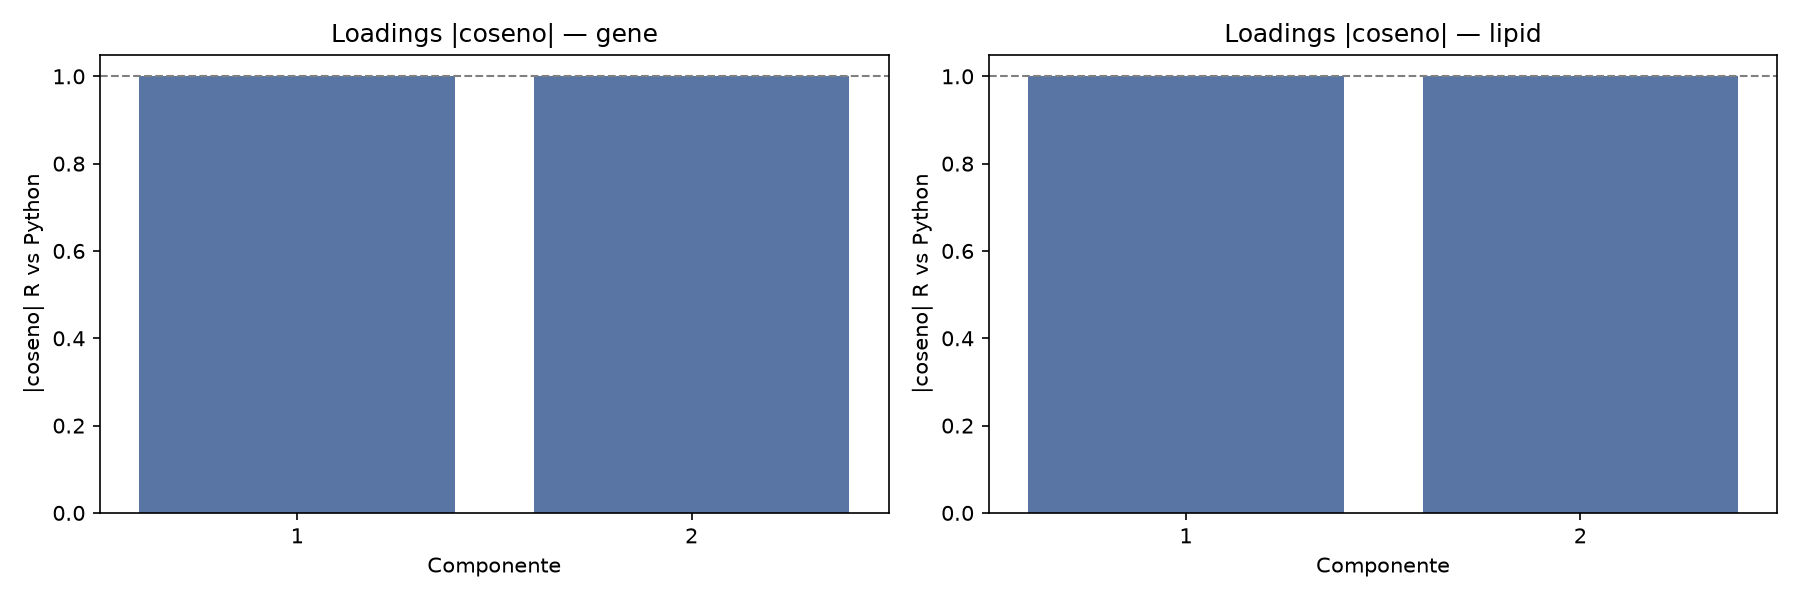

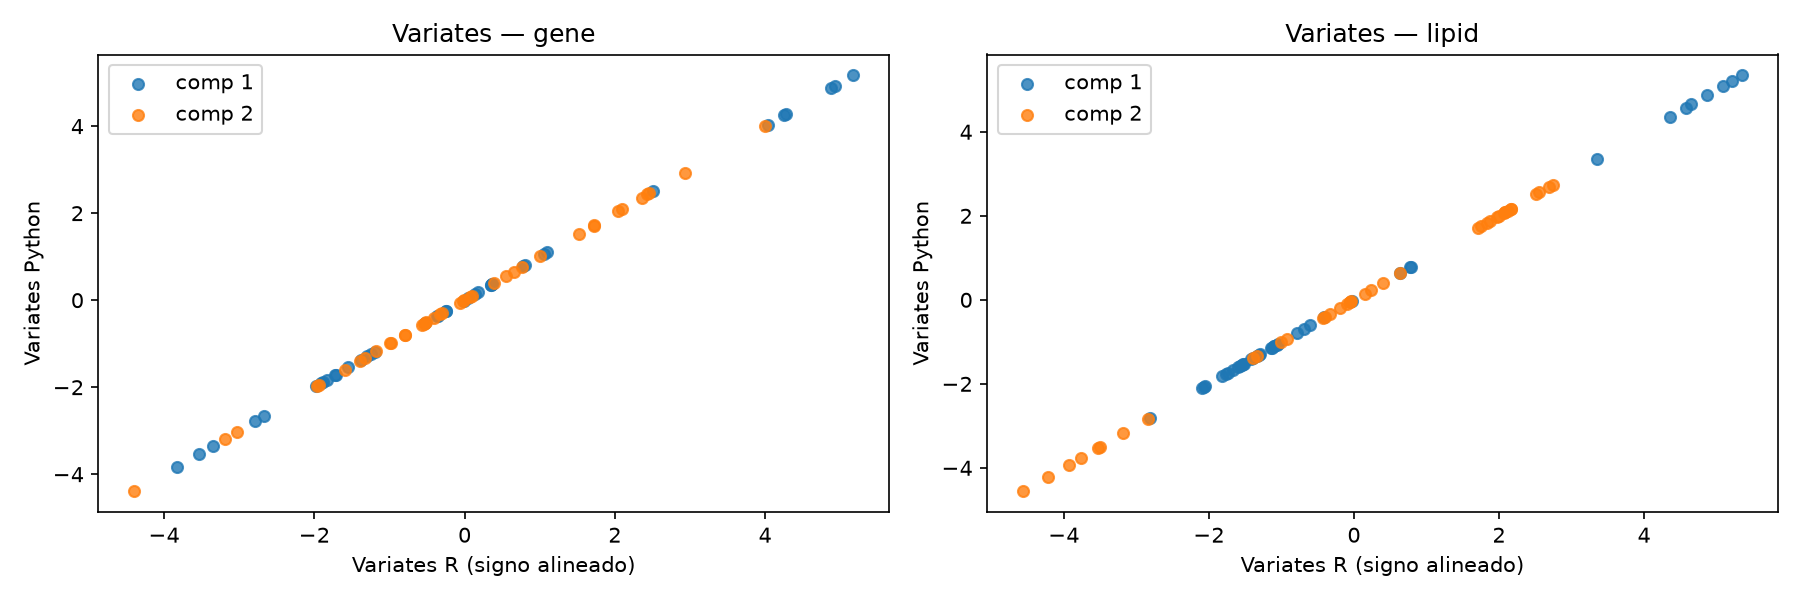

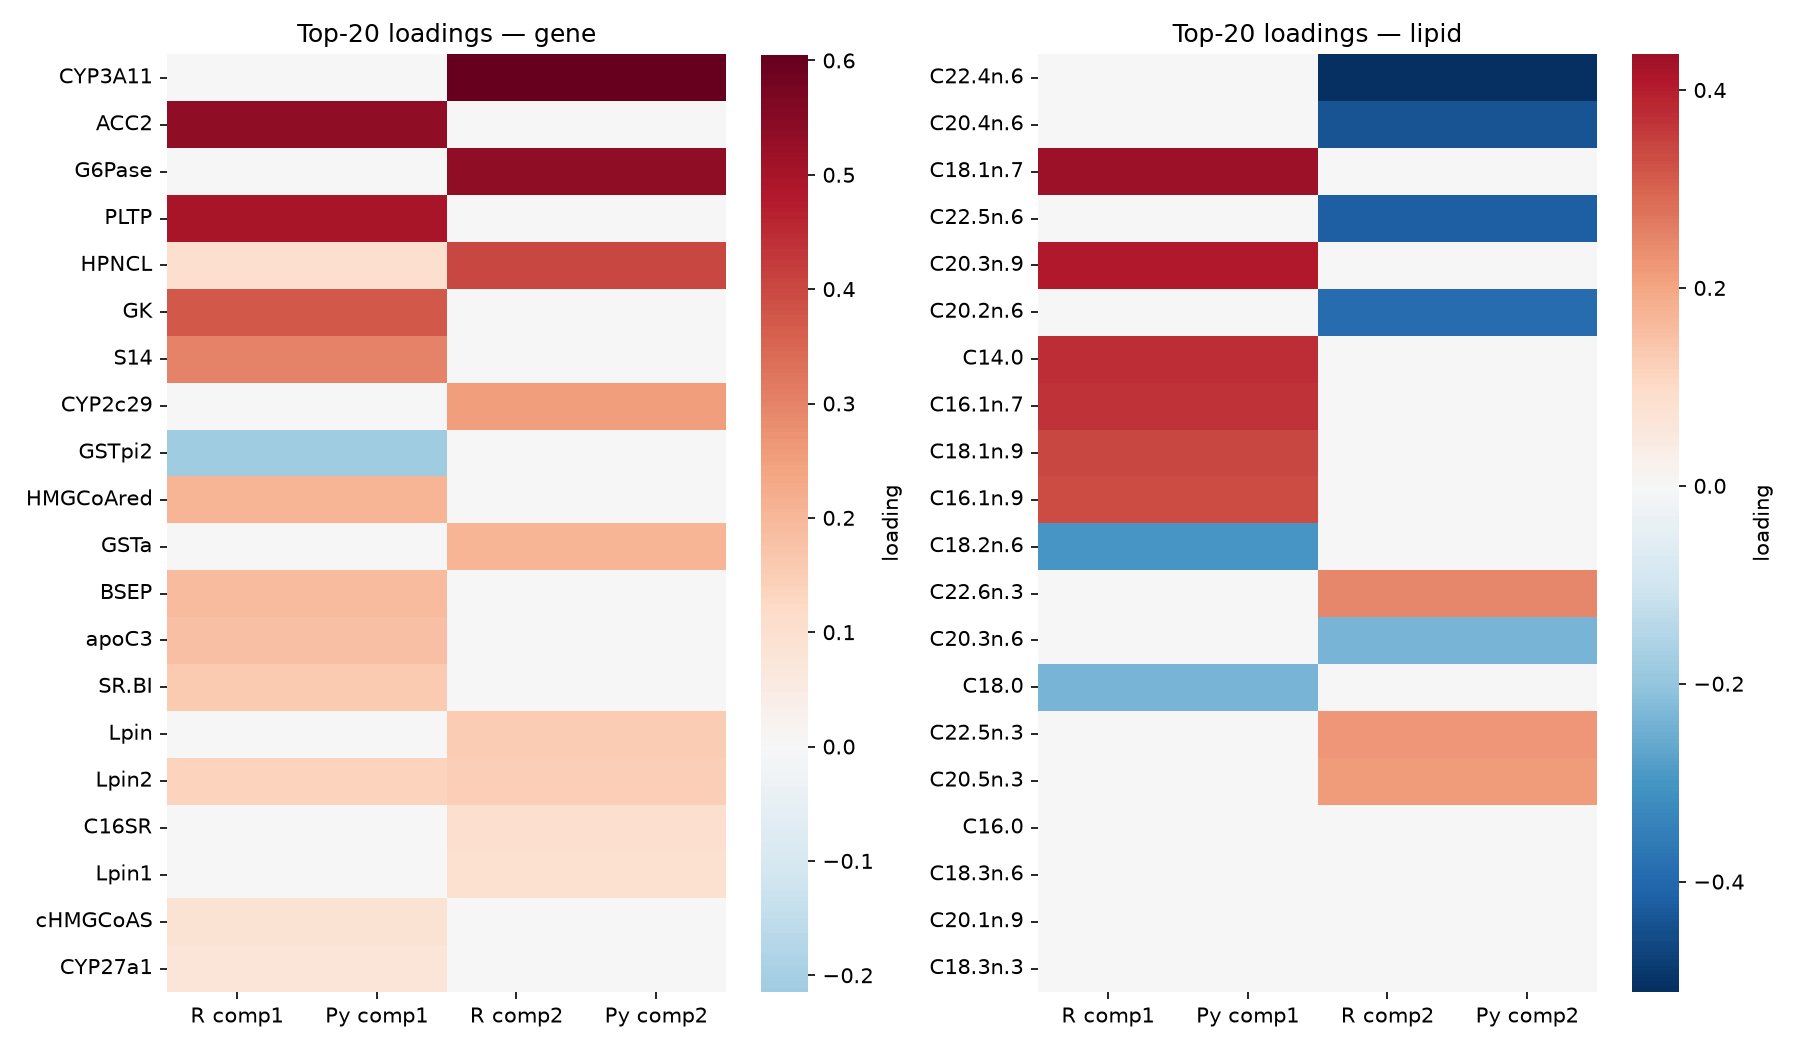

In [7]:
if comparison is not None:
    demo.save_plots(comparison, r_model, py_model, OUT_DIR)
    for name in [
        "comparison_cosines.png",
        "comparison_variates.png",
        "comparison_loadings.png",
    ]:
        path = OUT_DIR / name
        if path.exists():
            display(Image(filename=str(path)))
else:
    print("No hay comparación para graficar.")

## 6. Rutas adicionales solo en Python

Estas rutas no se comparan con R porque la API usada de mixOmics no expone
`tau` y MINT en R requiere `Y`.

In [8]:
py_unsup = demo.MINT(
    n_components=2,
    keepA=keep,
    tau=None,
    scale=True,
    max_iter=100,
    tol=1e-6,
    init="svd.single",
).fit(X_dict, study=study)

py_rgcca = demo.MINT(
    n_components=2,
    keepA=keep,
    tau="optimal",
    scale=True,
    max_iter=100,
    tol=1e-6,
    init="svd.single",
).fit(X_dict, study=study)

print(
    "MINT no supervisado -> ncomp:",
    py_unsup.n_components_,
    "| iter:",
    py_unsup._mint_result.iter,
)
print(
    "RGCCA (tau=optimal) -> ncomp:",
    py_rgcca.n_components_,
    "| iter:",
    py_rgcca._mint_result.iter,
)

MINT no supervisado -> ncomp: [2, 2] | iter: [5, 5]
RGCCA (tau=optimal) -> ncomp: [2, 2] | iter: [33, 20]


## 7. Resultados guardados

Se guardan en `results/mint_r_vs_python/`:
`comparison.csv`, `r_loadings_<block>.csv`, `py_loadings_<block>.csv`,
`config.json` y los PNG.

In [9]:
import json

config = {
    "dataset": "nutrimouse",
    "n_components": 2,
    "keepX": keep,
    "scale": True,
    "max_iter": 100,
    "tol": 1e-6,
    "study_source": "genotype",
    "r_backend": r_model.backend_ if r_model is not None else None,
    "r_ncomp": r_model.n_components_ if r_model is not None else None,
    "r_iter": r_model.iter_ if r_model is not None else None,
    "py_ncomp": py_model.n_components_,
    "py_iter": py_model._mint_result.iter,
    "py_unsup_iter": py_unsup._mint_result.iter,
    "py_rgcca_iter": py_rgcca._mint_result.iter,
}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2))

print("Guardado en:", OUT_DIR)
for path in sorted(OUT_DIR.glob("*")):
    print(" -", path.name)

Guardado en: /home/sephir/omics/results/mint_r_vs_python
 - comparison.csv
 - comparison_cosines.png
 - comparison_loadings.png
 - comparison_variates.png
 - config.json
 - py_loadings_gene.csv
 - py_loadings_lipid.csv
 - r_loadings_gene.csv
 - r_loadings_lipid.csv


## 8. Interpretación

Con `ncomp=2`, `keepX = {"gene": [15, 15], "lipid": [8, 8]}`, `Y = diet`
y `study = genotype`, R y Python coinciden: cosenos y correlaciones ≈ 1,
Jaccard = 1 e iteraciones `[7, 6]`.

Un valor menor a 1 no implica necesariamente un bug: puede deberse a empates
en la sparsidad, diferencias numéricas o distinta inicialización. Ver
`MINT_DISCREPANCIES.md` para las diferencias conocidas.

In [10]:
if comparison is not None:
    print(comparison.round(6).to_string(index=False))
    print("\nCoseno mínimo de loadings:", comparison["loading_cos_abs"].min())
    print("Jaccard mínimo:", comparison["jaccard"].min())
    print(
        "¿Mismas variables seleccionadas?",
        bool((comparison["jaccard"] == 1.0).all()),
    )
else:
    print("Sin R no hay comparación; se muestran las rutas Python.")

block  component  loading_cos_abs  loading_corr_abs  variate_cos_abs  n_selected_R  n_selected_Py  n_overlap  jaccard
 gene          1              1.0               1.0              1.0            15             15         15      1.0
 gene          2              1.0               1.0              1.0            15             15         15      1.0
lipid          1              1.0               1.0              1.0             8              8          8      1.0
lipid          2              1.0               1.0              1.0             8              8          8      1.0

Coseno mínimo de loadings: 0.9999999914281331
Jaccard mínimo: 1.0
¿Mismas variables seleccionadas? True
